# 02 – Weighting (στάθμιση): non-response adjustment + raking

Στο notebook 01 βρήκαμε δύο προβλήματα:
1. **Non-response bias:** μόνο το 51,9% του static panel έχει δημογραφικά, και αυτά τα νοικοκυριά ξοδεύουν πολύ περισσότερα (διάμεση 2.869$ vs 1.530$). Στο SQL 03 το ποσοστό απόκρισης ανεβαίνει από 20,6% στο πιο «ελαφρύ» 20% των νοικοκυριών σε 74,4% στο πιο «βαρύ».
2. **Μη αντιπροσωπευτικό δείγμα:** π.χ. ηλικίες 45–54 +15,6 μονάδες, 65+ −14,9 μονάδες σε σχέση με το Census.

Η στάθμιση γίνεται σε **2 στάδια**:
- **Στάδιο Α – Non-response adjustment (weighting classes):** μέσα σε κάθε πεμπτημόριο δαπάνης, τα νοικοκυριά με δημογραφικά «εκπροσωπούν» και όσα δεν έχουν. Βάρος = όλα τα νοικοκυριά της ομάδας / νοικοκυριά με δημογραφικά.
- **Στάδιο Β – Raking (Iterative Proportional Fitting, IPF):** προσαρμόζουμε τα βάρη ώστε τα σύνολα ανά ηλικία, εισόδημα και μέγεθος νοικοκυριού να ταιριάζουν με το Census (115,97 εκ. νοικοκυριά). Μετά **trimming** (κόψιμο ακραίων βαρών) και ξανά raking.

Συγκρίνουμε 3 σενάρια: **χωρίς στάθμιση**, **μόνο raking**, **non-response + raking**.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.chdir(r'C:\Projects\circana-panel-weighting')   # ο φάκελος του project
CLEAN, IMG, TARGETS = 'data-clean', 'images', 'data-targets'
pd.set_option('display.width', 140)

hh = pd.read_csv(f'{CLEAN}/households.csv')
static = hh[hh['static']].copy()
print('Static households:', len(static), '| with demographics:', static['has_demo'].sum())

Static households: 1406 | with demographics: 730


## 1. Ετοιμασία μεταβλητών
- Πεμπτημόρια δαπάνης (`pd.qcut`, 5 ίσες ομάδες) σε **όλο** το static panel. Είναι η ίδια λογική με το `NTILE(5)` του SQL 03.
- Εισόδημα: ενώνουμε τα 100–124K, 125–149K, 150–199K και 200K+ σε **100K+**, γιατί μερικά κελιά έχουν λίγα νοικοκυριά (π.χ. 200K+ = 16). Πολύ μικρά κελιά δίνουν τεράστια βάρη.

In [2]:
static['spend_quintile'] = pd.qcut(static['annual_spend'], 5, labels=[1, 2, 3, 4, 5]).astype(int)

high = ['100-124K', '125-149K', '150-199K', '200K+']
static['income_w'] = static['income'].replace({k: '100K+' for k in high})
static['hh_size'] = static['hh_size'].astype(str).str.replace('.0', '', regex=False)

targets = pd.read_csv(f'{TARGETS}/us_household_targets_acs2012.csv')
targets.loc[(targets['variable'] == 'income') & targets['category'].isin(high), 'category'] = '100K+'
targets = targets.groupby(['variable', 'category'], as_index=False)['households'].sum()
targets['variable'] = targets['variable'].replace({'income': 'income_w'})
ORDER = ['19-24', '25-34', '35-44', '45-54', '55-64', '65+',
         'Under 15K', '15-24K', '25-34K', '35-49K', '50-74K', '75-99K', '100K+',
         '1', '2', '3', '4', '5+']
targets['order'] = targets['category'].map(ORDER.index)
targets = targets.sort_values(['variable', 'order']).drop(columns='order').reset_index(drop=True)
POP = targets.loc[targets['variable'] == 'age', 'households'].sum()
print(f'Population households: {POP:,}')
targets

Population households: 115,969,540


,variable,category,households
0,age,19-24,4639337
1,age,25-34,17764964
2,age,35-44,20898156
3,age,45-54,24112796
4,age,55-64,22027067
5,age,65+,26527220
6,hh_size,1,32256217
7,hh_size,2,39026684
8,hh_size,3,18161094
9,hh_size,4,15130851


## 2. Στάδιο Α – Non-response adjustment
Για κάθε πεμπτημόριο: `nr_factor = νοικοκυριά / νοικοκυριά με δημογραφικά`.
**Έλεγχος εγκυρότητας:** ξέρουμε τη δαπάνη όλων των 1.406 νοικοκυριών, άρα ελέγχουμε αν μετά τη διόρθωση ο σταθμισμένος μέσος των «απαντησάντων» πλησιάζει τον πραγματικό μέσο όλου του panel.

In [3]:
nr = (static.groupby('spend_quintile')
            .agg(households=('household_key', 'size'),
                 respondents=('has_demo', 'sum'),
                 avg_spend=('annual_spend', 'mean'))
            .reset_index())
nr['response_rate_pct'] = (nr['respondents'] / nr['households'] * 100).round(1)
nr['nr_factor'] = (nr['households'] / nr['respondents']).round(3)
print(nr)

resp = static[static['has_demo']].copy()
resp = resp.merge(nr[['spend_quintile', 'nr_factor']], on='spend_quintile')
resp['w_nr'] = resp['nr_factor']

true_mean = static['annual_spend'].mean()
raw_mean = resp['annual_spend'].mean()
nr_mean = np.average(resp['annual_spend'], weights=resp['w_nr'])
print(f'\nMean annual spend – all static (truth): {true_mean:,.0f} $')
print(f'Respondents, unweighted             : {raw_mean:,.0f} $  (bias {raw_mean/true_mean*100-100:+.1f}%)')
print(f'Respondents, NR-adjusted            : {nr_mean:,.0f} $  (bias {nr_mean/true_mean*100-100:+.1f}%)')
print(f'Sum of NR weights: {resp["w_nr"].sum():.0f} (should equal {len(static)})')

   spend_quintile  households  respondents    avg_spend  response_rate_pct  nr_factor
0               1         282           58   753.874504               20.6      4.862
1               2         281          121  1457.597758               43.1      2.322
2               3         281          160  2230.066477               56.9      1.756
3               4         281          182  3305.793310               64.8      1.544
4               5         281          209  6261.118114               74.4      1.344

Mean annual spend – all static (truth): 2,800 $
Respondents, unweighted             : 3,436 $  (bias +22.7%)
Respondents, NR-adjusted            : 2,835 $  (bias +1.3%)
Sum of NR weights: 1406 (should equal 1406)


## 3. Στάδιο Β – Raking (IPF)
Ο αλγόριθμος, με απλά λόγια:
1. Διορθώνουμε τα βάρη ώστε τα σύνολα ανά **ηλικία** να ισούνται με το Census (πολλαπλασιάζουμε κάθε κατηγορία με στόχος / τρέχον σύνολο).
2. Το ίδιο για το **εισόδημα**: αυτό «χαλάει» λίγο την ηλικία.
3. Το ίδιο για το **μέγεθος νοικοκυριού**.
4. Επαναλαμβάνουμε μέχρι να ταιριάζουν όλα ταυτόχρονα (σύγκλιση = convergence).

Το raking ταιριάζει τα **περιθώρια** (margins) κάθε μεταβλητής, όχι τους συνδυασμούς τους (π.χ. 65+ ΚΑΙ κάτω από 15K), γιατί για τους συνδυασμούς δεν έχουμε αρκετό δείγμα.

In [4]:
RAKE_VARS = ['age', 'income_w', 'hh_size']

def rake(df, start_weight, targets, variables, max_iter=100, tol=1e-6):
    w = df[start_weight].astype(float).copy()
    w = w / w.sum() * POP                       # scale to the population total
    for it in range(1, max_iter + 1):
        max_diff = 0
        for var in variables:
            t = targets[targets['variable'] == var].set_index('category')['households']
            current = w.groupby(df[var]).sum()
            factor = (t / current).reindex(df[var]).to_numpy()
            w = w * factor
            max_diff = max(max_diff, (abs(current - t) / t).max())
        if max_diff < tol:
            return w, it
    print('WARNING: raking did not converge')
    return w, max_iter

def diagnostics(w, name):
    n = len(w)
    deff = n * (w ** 2).sum() / w.sum() ** 2          # Kish design effect from weighting
    rel = w / w.mean()
    return {'scenario': name, 'n': n, 'min_rel_w': round(rel.min(), 2), 'max_rel_w': round(rel.max(), 2),
            'max/min': round(rel.max() / rel.min(), 1), 'deff_kish': round(deff, 2),
            'eff_sample_size': round(n / deff), 'efficiency_pct': round(100 / deff, 1)}

missing = resp[RAKE_VARS].isna().sum()
print('Missing values in rake variables:', missing.to_dict())

resp['w_one'] = 1.0
resp['w_rake_only'], it_a = rake(resp, 'w_one', targets, RAKE_VARS)
resp['w_nr_rake'], it_b = rake(resp, 'w_nr', targets, RAKE_VARS)
print(f'Converged: rake only in {it_a} iterations, NR + rake in {it_b} iterations')

Missing values in rake variables: {'age': 0, 'income_w': 0, 'hh_size': 0}
Converged: rake only in 9 iterations, NR + rake in 9 iterations


## 4. Trimming (κόψιμο ακραίων βαρών)
Ένα νοικοκυριό με πολύ μεγάλο βάρος «μετράει» για εκατοντάδες άλλα: αν έχει κάνει μια ασυνήθιστη αγορά, χαλάει όλη την εκτίμηση.
Κανόνας: σχετικό βάρος (βάρος / μέσο βάρος) ανάμεσα σε **0,25 και 5**. Κόβουμε, ξανακάνουμε raking και επαναλαμβάνουμε μέχρι όλα τα βάρη να είναι μέσα στα όρια (με ανοχή 5%).
Υπάρχει **trade-off**: λιγότερη διακύμανση (μεγαλύτερο effective sample size), αλλά τα περιθώρια μπορεί να μην ταιριάζουν 100%.

In [5]:
LOW, HIGH = 0.25, 5.0

def trim_and_rake(df, col, rounds=20):
    tmp = df.copy()
    for r in range(1, rounds + 1):
        rel = tmp[col] / tmp[col].mean()
        if rel.min() >= LOW * 0.95 and rel.max() <= HIGH * 1.05:
            return tmp[col], r - 1
        tmp[col] = rel.clip(LOW, HIGH) * tmp[col].mean()
        tmp[col], _ = rake(tmp, col, targets, RAKE_VARS)
    print('WARNING: weights still outside the limits after', rounds, 'rounds')
    return tmp[col], rounds

resp['w_final'], rounds = trim_and_rake(resp, 'w_nr_rake')
print('Trim-and-rake rounds:', rounds)
rel = resp['w_final'] / resp['w_final'].mean()
print(f'Final relative weights: min {rel.min():.2f}, max {rel.max():.2f}')

diag = pd.DataFrame([diagnostics(resp['w_one'] * POP / len(resp), 'unweighted'),
                     diagnostics(resp['w_rake_only'], 'rake only'),
                     diagnostics(resp['w_nr_rake'], 'NR + rake'),
                     diagnostics(resp['w_final'], 'NR + rake, trimmed')])
diag

Trim-and-rake rounds: 3
Final relative weights: min 0.24, max 5.21


,scenario,n,min_rel_w,max_rel_w,max/min,deff_kish,eff_sample_size,efficiency_pct
0,unweighted,730,1.00,1.00,1.0,1.00,730,100.0
1,rake only,730,0.22,9.36,43.1,2.02,361,49.5
2,NR + rake,730,0.16,9.76,61.3,2.30,318,43.6
3,"NR + rake, trimmed",730,0.24,5.21,21.5,2.13,342,46.9


## 5. Έλεγχος: ταιριάζουν τα περιθώρια με το Census;
Για κάθε κατηγορία: % στο δείγμα χωρίς στάθμιση, % μετά την τελική στάθμιση, % στο Census.

In [6]:
rows = []
for var in RAKE_VARS:
    t = targets[targets['variable'] == var].set_index('category')['households']
    unw = resp[var].value_counts(normalize=True) * 100
    fin = resp.groupby(var)['w_final'].sum() / resp['w_final'].sum() * 100
    for cat in t.index:
        rows.append([var, cat, round(unw.get(cat, 0), 1), round(fin.get(cat, 0), 1), round(t[cat] / POP * 100, 1)])
margins = pd.DataFrame(rows, columns=['variable', 'category', 'unweighted_pct', 'weighted_pct', 'census_pct'])
margins['abs_diff_after'] = (margins['weighted_pct'] - margins['census_pct']).abs().round(1)
print('Max absolute difference after weighting:', margins['abs_diff_after'].max(), 'pp')
margins

Max absolute difference after weighting: 0.0 pp


,variable,category,unweighted_pct,weighted_pct,census_pct,abs_diff_after
0,age,19-24,5.3,4.0,4.0,0.0
1,age,25-34,18.2,15.3,15.3,0.0
2,age,35-44,24.5,18.0,18.0,0.0
3,age,45-54,36.4,20.8,20.8,0.0
4,age,55-64,7.5,19.0,19.0,0.0
5,age,65+,7.9,22.9,22.9,0.0
6,income_w,Under 15K,7.1,13.3,13.3,0.0
7,income_w,15-24K,9.3,11.1,11.1,0.0
8,income_w,25-34K,9.5,10.4,10.4,0.0
9,income_w,35-49K,22.1,13.8,13.8,0.0


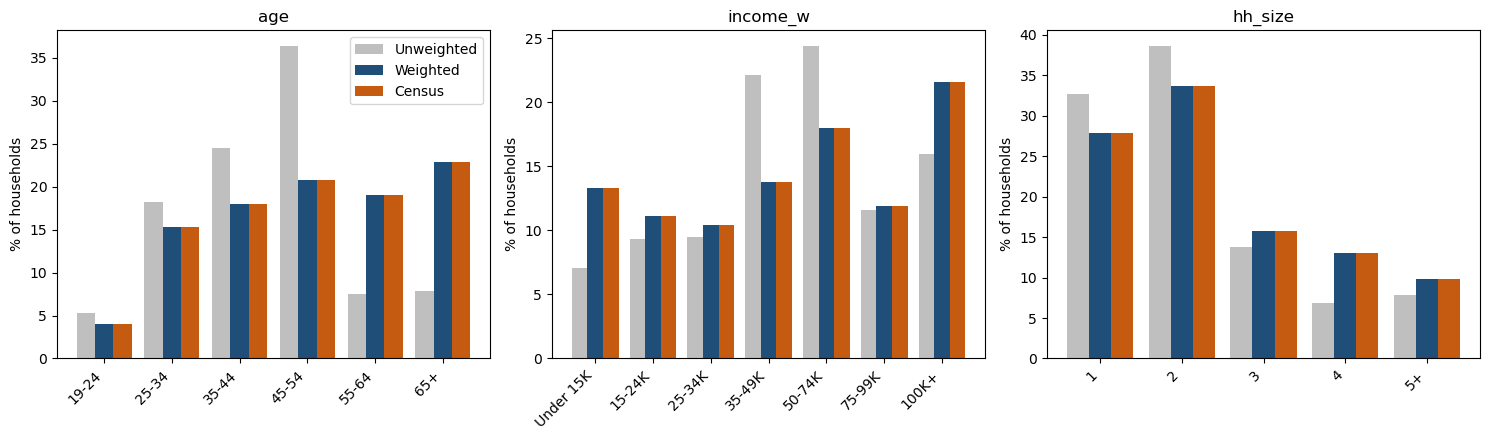

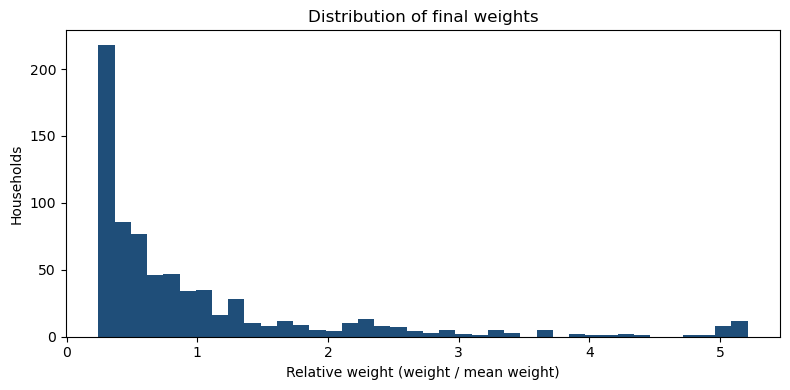

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, var in zip(axes, RAKE_VARS):
    m = margins[margins['variable'] == var]
    x = np.arange(len(m))
    ax.bar(x - 0.27, m['unweighted_pct'], 0.27, label='Unweighted', color='#bfbfbf')
    ax.bar(x, m['weighted_pct'], 0.27, label='Weighted', color='#1f4e79')
    ax.bar(x + 0.27, m['census_pct'], 0.27, label='Census', color='#c55a11')
    ax.set_xticks(x); ax.set_xticklabels(m['category'], rotation=45, ha='right')
    ax.set_title(var); ax.set_ylabel('% of households')
axes[0].legend()
plt.tight_layout(); plt.savefig(f'{IMG}/margins_before_after.png', dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(resp['w_final'] / resp['w_final'].mean(), bins=40, color='#1f4e79')
ax.set_xlabel('Relative weight (weight / mean weight)'); ax.set_ylabel('Households')
ax.set_title('Distribution of final weights')
plt.tight_layout(); plt.savefig(f'{IMG}/weight_distribution.png', dpi=120); plt.show()

## 6. Ποια νοικοκυριά έχουν τα μεγαλύτερα βάρη;
Είναι αυτά που ανήκουν σε ομάδες που λείπουν από το δείγμα. Είναι χρήσιμο να το ξέρουμε, γιατί αυτά επηρεάζουν περισσότερο τις εκτιμήσεις.

In [8]:
resp['rel_w'] = (resp['w_final'] / resp['w_final'].mean()).round(2)
print(resp.sort_values('rel_w', ascending=False)
          [['household_key', 'age', 'income_w', 'hh_size', 'spend_quintile', 'annual_spend', 'rel_w']]
          .head(10).to_string(index=False))

resp[['household_key', 'spend_quintile', 'nr_factor', 'w_rake_only', 'w_nr_rake', 'w_final']] \
    .to_csv(f'{CLEAN}/weights.csv', index=False)
diag.to_csv(f'{CLEAN}/weight_diagnostics.csv', index=False)
margins.to_csv(f'{CLEAN}/margins_check.csv', index=False)
print('\nSaved weights.csv, weight_diagnostics.csv, margins_check.csv')

 household_key   age  income_w hh_size  spend_quintile  annual_spend  rel_w
           631   65+     100K+       3               5       5092.68   5.21
           779   65+     100K+       3               3       2482.99   5.21
          2337   65+ Under 15K       3               5       5947.99   5.20
          1364   65+     100K+       1               2       1286.80   5.19
           462   65+     100K+       1               1        852.12   5.19
          1797   65+ Under 15K       1               4       3390.88   5.18
            56 55-64     100K+       4               5       4152.98   5.15
          2282 55-64     100K+       1               1        726.07   5.13
            42   65+    50-74K       1               1       1084.47   5.13
           460   65+    25-34K       1               1        374.41   5.12

Saved weights.csv, weight_diagnostics.csv, margins_check.csv
